# JPEG Simulator

## Base processing of image

In [1]:
import numpy as np
import cv2
import scipy

# Google Colab's OpenCV image display function
from google.colab.patches import cv2_imshow

# to upload images on Colab
from google.colab import files
uploaded = files.upload()

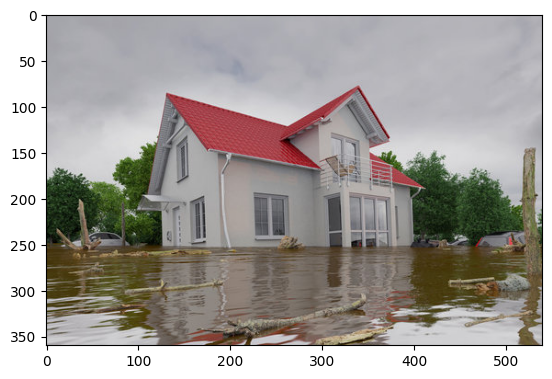

In [2]:
image = cv2.imread('example.jpg')
image_show = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

l, w, _ = image.shape

import matplotlib.pyplot as plt
plt.imshow(image_show)

## Encoding Process

### 4:2:0 Subsampling

In [3]:
YCrCb = cv2.cvtColor(image, cv2.COLOR_BGR2YCR_CB)
Y = YCrCb[:,:,0]
Cr = YCrCb[:,:,1]
Cb = YCrCb[:,:,2]

# For 4:2:0
Cr_half = scipy.ndimage.zoom(Cr, zoom=0.5, order=1)
Cb_half = scipy.ndimage.zoom(Cb, zoom=0.5, order=1)

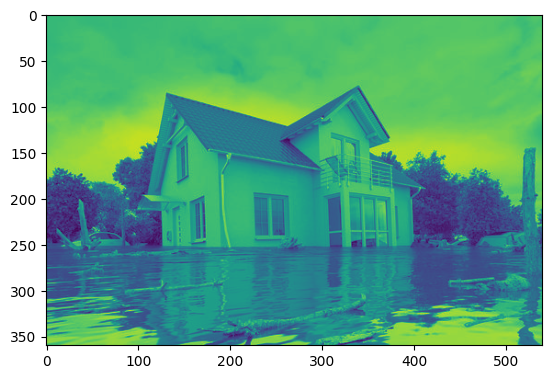

In [4]:
plt.imshow(Y)

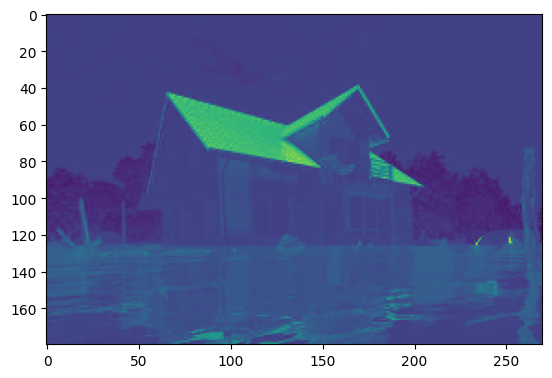

In [ ]:
plt.imshow(Cr_half)

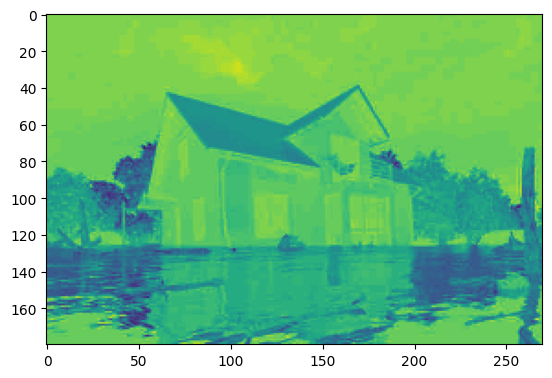

In [ ]:
plt.imshow(Cb_half)

### Division into blocks

In [4]:
pip install patchify

In [5]:
from patchify import patchify
Y_blocks = patchify(Y, (8, 8), step=8)
Cr_blocks = patchify(Cr_half, (8, 8), step=8)
Cb_blocks = patchify(Cb_half, (8, 8), step=8)

print(Y_blocks.shape)
print(Cr_blocks.shape)
print(Cb_blocks.shape)

(45, 67, 8, 8)
(22, 33, 8, 8)
(22, 33, 8, 8)


### DCT, Quantization, and Zig-zag Scanning

In [19]:
Y_quantization_matrix = [
    [16, 11, 10, 16, 24, 40, 51, 61],
    [12, 12, 14, 19, 26, 58, 60, 55],
    [14, 13, 16, 24, 40, 57, 69, 56],
    [14, 17, 22, 29, 51, 87, 80, 62],
    [18, 22, 37, 56, 68, 109, 103, 77],
    [24, 35, 55, 64, 81, 104, 113, 92],
    [49, 64, 78, 87, 103, 121, 120, 101],
    [72, 92, 95, 98, 112, 100, 103, 99]
]

C_quantization_matrix = [
    [17, 18, 24, 47, 99, 99, 99, 99],
    [18, 21, 26, 66, 99, 99, 99, 99],
    [24, 26, 56, 99, 99, 99, 99, 99],
    [47, 66, 99, 99, 99, 99, 99, 99],
    [99, 99, 99, 99, 99, 99, 99, 99],
    [99, 99, 99, 99, 99, 99, 99, 99],
    [99, 99, 99, 99, 99, 99, 99, 99],
    [99, 99, 99, 99, 99, 99, 99, 99]
]

def encode(blocks, type='L'):
  x, y, _, _ = blocks.shape
  encoded = [[[] for _ in range(y)] for _ in range(x)]
  for i in range(x):
    for j in range(y):
      dct_transformed = scipy.fft.dct(blocks[i, j, :, :])
      if type == 'C':
        dct_transformed = np.round(dct_transformed / C_quantization_matrix).astype(np.int32)
      else:
        dct_transformed = np.round(dct_transformed / Y_quantization_matrix).astype(np.int32)
      encoded[i][j] = zigzag_scan(dct_transformed)
  return encoded

def zigzag_scan(block):
  rows, cols, = block.shape
  result = []
  r, c = 0, 0
  going_down = True

  while len(result) < rows * cols:
    result.append(block[r][c])
    if going_down:
      if c == 0 or r == rows - 1:
        going_down = False
        if r == rows - 1: c += 1
        else: r += 1
      else:
        r += 1
        c -= 1
    else:
      if r == 0 or c == cols - 1:
        going_down = True
        if c == cols - 1: r += 1
        else: c += 1
      else:
        r -= 1
        c += 1
  return result

In [20]:
Y_blocks_encoded = encode(Y_blocks, 'L')
Cr_blocks_encoded = encode(Cr_blocks, 'C')
Cb_blocks_encoded = encode(Cb_blocks, 'C')

In [21]:
print(Y_blocks_encoded[7][3])
print(Cr_blocks_encoded[7][3])
print(Cb_blocks_encoded[7][3])

[169, 225, 0, 0, 0, 193, 193, 0, 0, 0, 0, 0, 0, 0, 151, 113, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 55, 38, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
[120, 114, 0, 0, 0, 85, 44, 0, 0, 0, 0, 0, 0, 0, 21, 21, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 21, 21, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
[122, 116, 0, 0, 0, 87, 44, 0, 0, 0, 0, 0, 0, 0, 21, 21, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 21, 21, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


## Decoding

In [37]:
def decode(arrays, type = 'L'):
  x, y, _ = np.array(arrays).shape
  decoded = [[[] for _ in range(y)] for _ in range(x)]
  for i in range(x):
    for j in range(y):
      block = inverse_zigzag(arrays[i][j]).T
      if type == 'C':
        block = block * C_quantization_matrix
      else: block = block * Y_quantization_matrix
      decoded[i][j] = (scipy.fft.idct(block)).astype(np.uint8)
  return np.array(decoded)

def inverse_zigzag(array):
  output = np.zeros((8, 8))
  r = 0
  c = 0
  i = 0
  while i < len(array):
    output[r, c] = array[i]
    if (r + c) % 2 == 0:
      if c < 8 - 1 and r > 0:
        r -= 1
        c += 1
      elif c == 8 - 1: r += 1
      elif r == 0: c += 1
    else:
      if r < 8 - 1 and c > 0:
        r += 1
        c -= 1
      elif r == 8 - 1: c += 1
      elif c == 0: r += 1
    i += 1
  return output

In [38]:
Y_blocks_decoded = decode(Y_blocks_encoded, 'L')
Cr_blocks_decoded = decode(Cr_blocks_encoded, 'C')
Cb_blocks_decoded = decode(Cb_blocks_encoded, 'C')

In [44]:
from patchify import unpatchify
x_y, y_y, _, _ = Y_blocks_decoded.shape
x_c, y_c, _, _ = Cr_blocks_decoded.shape
reconstructed_Y = unpatchify(Y_blocks_decoded, (x_y * 8, y_y * 8))
reconstructed_Cr = unpatchify(Cr_blocks_decoded, (x_c * 8, y_c * 8))
reconstructed_Cb = unpatchify(Cb_blocks_decoded, (x_c * 8, y_c * 8))

zoom_factors = [t / s for s, t in zip(reconstructed_Cr.shape, reconstructed_Y.shape)]

reconstructed_Cr_full = scipy.ndimage.zoom(reconstructed_Cr, zoom_factors, order=1)
reconstructed_Cb_full = scipy.ndimage.zoom(reconstructed_Cb, zoom_factors, order=1)

image_reconstructed = cv2.merge((reconstructed_Y, reconstructed_Cr_full, reconstructed_Cb_full))
print(image_reconstructed.shape)

(360, 536, 3)


In [42]:
image_new = cv2.cvtColor(image_reconstructed, cv2.COLOR_YCrCb2RGB)

## Original Image vs. Reconstructed Image

Text(0.5, 1.0, 'Reconstructed Image')

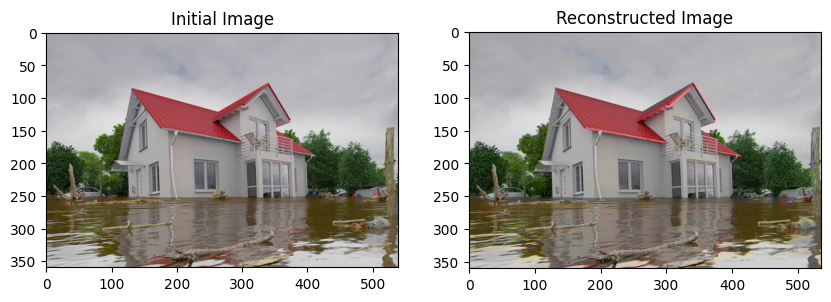

In [45]:
fig = plt.figure(figsize=(10, 6))

plt.subplot(121)
plt.imshow(image_show)
plt.title("Initial Image")
plt.subplot(122)
plt.imshow(image_new)
plt.title("Reconstructed Image")